# Telangana Tourism Data Cleaning & Analysis — Complete Project

This notebook follows the structure of the supplied Delhi Air Pollution analysis example, adapted to the available Telangana tourism dataset.

1. Data cleaning and validation
2. Bar chart — top 10 districts by total visitors
3. Heatmap — monthly visitors by district
4. Box plot — visitor distribution by tourism category
5. Pie chart — domestic vs foreign visitors
6. Line chart — monthly visitor trend
7. Clear chart titles, axes, labels and legends
8. Final project summary and output verification

**Input:** `telangana_tourism_2024_2025.csv` (kept beside this notebook in the project folder).  
**Outputs:** `cleaned_telangana_tourism.csv`, summary CSV files, and chart images in `visualizations/`.

**Data note:** the notebook analyzes the supplied dataset as provided. It checks internal consistency, but does not independently verify whether visitor counts and revenue are official published statistics. The data has 288 records, 12 district labels, and monthly records for 2024–2025. No latitude/longitude fields are supplied, so this notebook does not invent a geographic map.

## 1. Import libraries and load the dataset

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
BASE_DIR = Path(".")
OUTPUT_DIR = BASE_DIR / "visualizations"
OUTPUT_DIR.mkdir(exist_ok=True)

CSV_PATH = BASE_DIR / "telangana_tourism_2024_2025.csv"
if not CSV_PATH.exists():
    raise FileNotFoundError(
        "Place telangana_tourism_2024_2025.csv in the same folder as this notebook."
    )

df = pd.read_csv(CSV_PATH)
print("Original shape:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-7f8fuipl because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Original shape: (288, 14)


,Year,Month,Month_Number,Date,District,Region,Tourism_Category,Key_Tourist_Attractions,Historical_Significance,Domestic_Visitors,Foreign_Visitors,Total_Visitors,Avg_Hotel_Occupancy_%,Est_Revenue_Lakhs_INR
0,2024,Jan,1,2024-01-01,Hyderabad,Central Telangana,Heritage & Urban,"Golconda Fort, Charminar, Qutb Shahi Tombs, Ch...",Capital of Qutb Shahi Dynasty & Asaf Jahi (Niz...,235125,3872,238997,81.0,7647.90
1,2024,Jan,1,2024-01-01,Hanamkonda & Warangal,Eastern Telangana,Heritage & Pilgrimage,"Warangal Fort, Kakatiya Kala Thoranam, Thousan...",Capital of the medieval Kakatiya Dynasty (12th...,97810,433,98243,63.5,1768.37
2,2024,Jan,1,2024-01-01,Mulugu,Eastern Telangana,UNESCO Heritage & Eco-Tourism,"Ramappa Temple (UNESCO World Heritage), Medara...",Home to Kakatiya-era floating-brick architectu...,115825,313,116138,57.5,1742.07
3,2024,Jan,1,2024-01-01,Yadadri Bhuvanagiri,Central Telangana,Spiritual & Fort Heritage,"Yadadri Sri Lakshmi Narasimha Swamy Temple, Bh...",Monolithic rock fort of Western Chalukyas (10t...,183170,131,183301,66.6,2566.21
4,2024,Jan,1,2024-01-01,Nalgonda,Southern Telangana,Heritage & Eco-Tourism,"Nagarjuna Sagar Dam, Nagarjunakonda Buddhist M...",Ancient Ikshvaku dynasty Buddhist settlement &...,84834,197,85031,53.6,1360.50



Column names:
['Year', 'Month', 'Month_Number', 'Date', 'District', 'Region', 'Tourism_Category', 'Key_Tourist_Attractions', 'Historical_Significance', 'Domestic_Visitors', 'Foreign_Visitors', 'Total_Visitors', 'Avg_Hotel_Occupancy_%', 'Est_Revenue_Lakhs_INR']


## 2. Data cleaning and validation

In [2]:
data = df.copy()

# Standardize column names for consistent Python access.
data.columns = (data.columns.str.strip()
                .str.lower()
                .str.replace(r"[^a-z0-9]+", "_", regex=True)
                .str.strip("_"))

# Trim spaces in text fields.
for col in data.select_dtypes(include=["object", "string"]).columns:
    data[col] = data[col].astype("string").str.strip()

# Parse dates and convert numeric fields.
if "date" in data.columns:
    data["date"] = pd.to_datetime(data["date"], errors="coerce")

numeric_candidates = [
    "year", "month_number", "domestic_visitors", "foreign_visitors",
    "total_visitors", "avg_hotel_occupancy", "est_revenue_lakhs_inr"
]
for col in numeric_candidates:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")

before = len(data)
data = data.drop_duplicates().copy()
duplicates_removed = before - len(data)

# Keep rows with missing critical measures visible in the quality report.
critical = [c for c in ["date", "district", "domestic_visitors",
                         "foreign_visitors", "total_visitors"] if c in data.columns]
missing_critical = int(data[critical].isna().any(axis=1).sum()) if critical else 0

# Fill missing values only in numeric analysis fields with their median.
# Text and date values are not fabricated.
for col in data.select_dtypes(include="number").columns:
    if data[col].isna().any():
        median_value = data[col].median()
        if pd.notna(median_value):
            data[col] = data[col].fillna(median_value)

# Add a validation flag rather than silently rewriting total visitor values.
if {"domestic_visitors", "foreign_visitors", "total_visitors"}.issubset(data.columns):
    data["visitor_total_matches_components"] = (
        data["total_visitors"].eq(data["domestic_visitors"] + data["foreign_visitors"])
    )

data.to_csv(BASE_DIR / "cleaned_telangana_tourism.csv", index=False)

quality_report = pd.DataFrame({
    "Check": [
        "Original rows", "Rows after duplicate removal", "Duplicate rows removed",
        "Missing cells after cleaning", "Rows missing critical fields",
        "Rows where total visitors match domestic + foreign"
    ],
    "Result": [
        len(df), len(data), duplicates_removed, int(data.isna().sum().sum()),
        missing_critical,
        int(data["visitor_total_matches_components"].sum())
        if "visitor_total_matches_components" in data.columns else "Not available"
    ]
})
display(quality_report)
quality_report.to_csv(BASE_DIR / "data_quality_report.csv", index=False)
print("Saved cleaned dataset: cleaned_telangana_tourism.csv")

,Check,Result
0,Original rows,288
1,Rows after duplicate removal,288
2,Duplicate rows removed,0
3,Missing cells after cleaning,0
4,Rows missing critical fields,0
5,Rows where total visitors match domestic + for...,288


Saved cleaned dataset: cleaned_telangana_tourism.csv


## 3. Bar chart — top 10 districts by total visitors

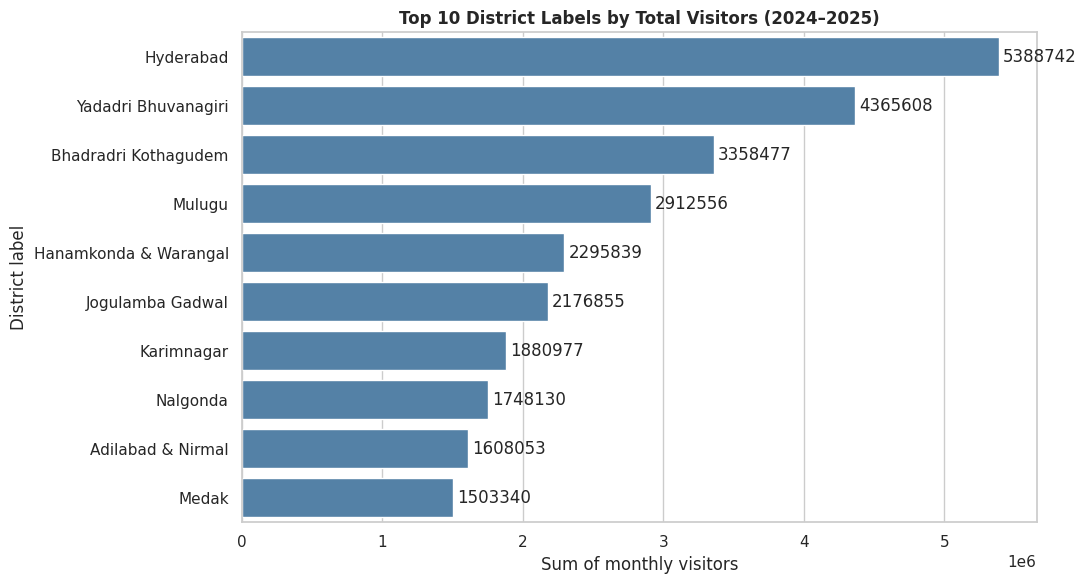

District labels available: 12


In [3]:
required = {"district", "total_visitors"}
if not required.issubset(data.columns):
    print("Cannot create district ranking: district and total_visitors columns are required.")
else:
    district_visitors = (data.groupby("district", dropna=True)["total_visitors"]
                         .sum().sort_values(ascending=False).head(10))
    plt.figure(figsize=(11, 6))
    ax = sns.barplot(x=district_visitors.values, y=district_visitors.index, color="steelblue")
    ax.set_title("Top 10 District Labels by Total Visitors (2024–2025)", weight="bold")
    ax.set_xlabel("Sum of monthly visitors")
    ax.set_ylabel("District label")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", padding=3)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "01_top_10_districts_by_visitors.png", dpi=300, bbox_inches="tight")
    plt.show()
    district_visitors.rename("total_visitors_2024_2025").to_csv(BASE_DIR / "district_visitor_summary.csv")
    print(f"District labels available: {data['district'].nunique()}")

## 4. Heatmap — monthly visitors by district

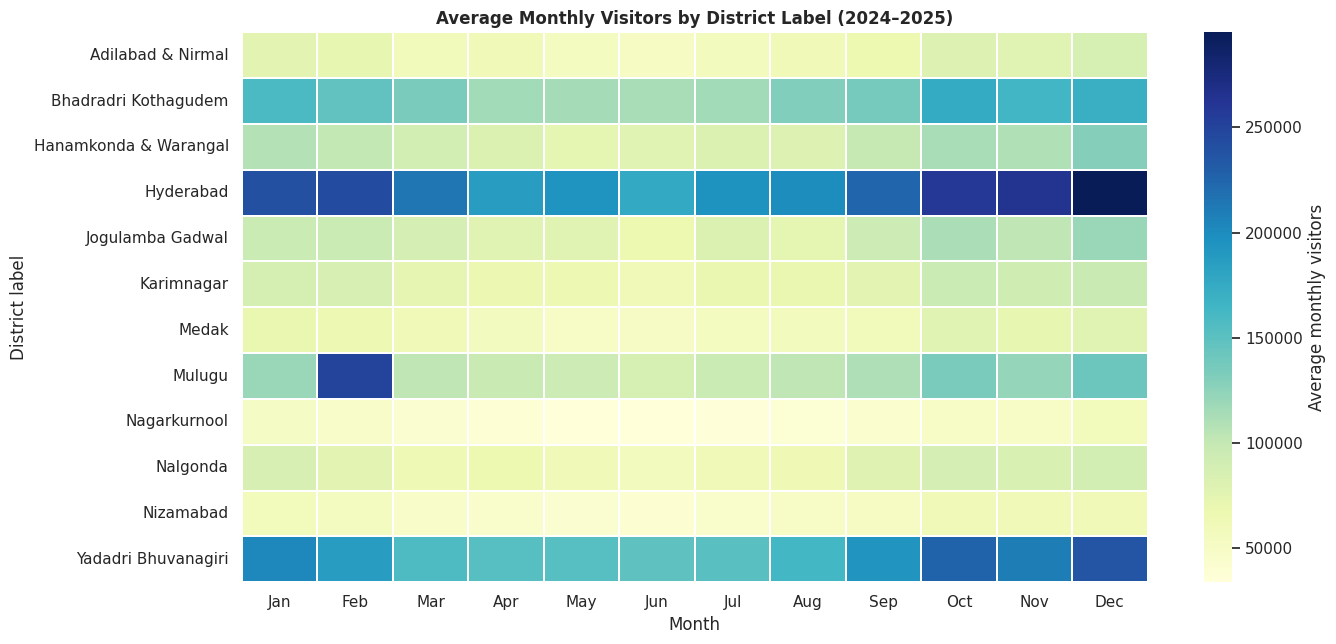

In [4]:
if {"month_number", "district", "total_visitors"}.issubset(data.columns):
    month_labels = (data[["month_number", "month"]].drop_duplicates()
                    .sort_values("month_number").set_index("month_number")["month"].to_dict())
    heat = data.pivot_table(index="district", columns="month_number",
                            values="total_visitors", aggfunc="mean")
    heat = heat.reindex(columns=sorted(heat.columns))
    heat.columns = [month_labels.get(c, str(c)) for c in heat.columns]
    plt.figure(figsize=(14, max(5, 0.55 * len(heat))))
    sns.heatmap(heat, cmap="YlGnBu", linewidths=0.25,
                cbar_kws={"label": "Average monthly visitors"})
    plt.title("Average Monthly Visitors by District Label (2024–2025)", weight="bold")
    plt.xlabel("Month")
    plt.ylabel("District label")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "02_monthly_visitors_heatmap.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("Heatmap requires month_number, district and total_visitors columns.")

## 5. Box plot — visitor distribution by tourism category

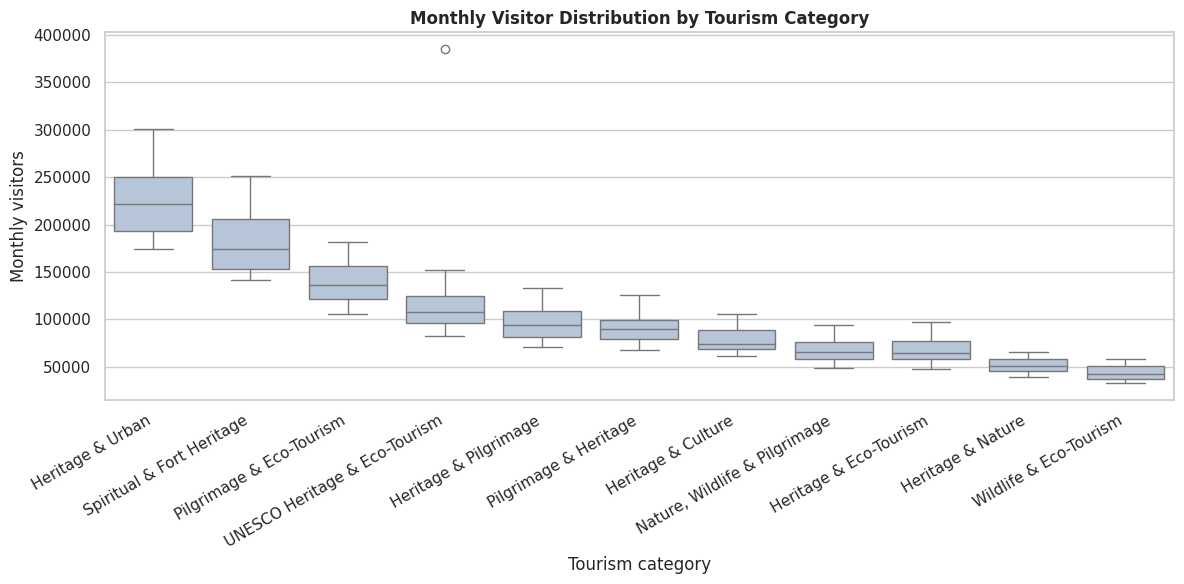

In [5]:
if {"tourism_category", "total_visitors"}.issubset(data.columns):
    plt.figure(figsize=(12, 6))
    order = (data.groupby("tourism_category")["total_visitors"].median()
             .sort_values(ascending=False).index)
    ax = sns.boxplot(data=data, x="tourism_category", y="total_visitors",
                     order=order, color="lightsteelblue")
    ax.set_title("Monthly Visitor Distribution by Tourism Category", weight="bold")
    ax.set_xlabel("Tourism category")
    ax.set_ylabel("Monthly visitors")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "03_visitors_by_category_boxplot.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("Box plot requires tourism_category and total_visitors columns.")

## 6. Pie chart — domestic vs foreign visitors

This chart compares the total visitor counts across the dataset period. It should be interpreted as the domestic/foreign split in this supplied dataset, not as a separately verified official statistic.

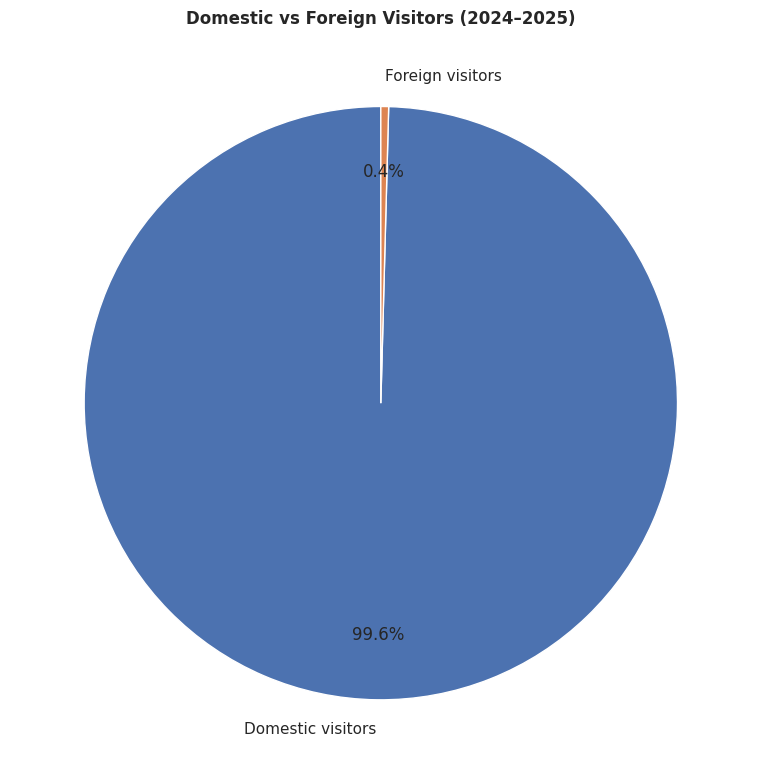

In [6]:
visitor_columns = [c for c in ["domestic_visitors", "foreign_visitors"] if c in data.columns]
if len(visitor_columns) == 2:
    totals = data[visitor_columns].sum().clip(lower=0)
    if totals.sum() > 0:
        plt.figure(figsize=(8, 8))
        plt.pie(totals.values, labels=["Domestic visitors", "Foreign visitors"],
                autopct="%1.1f%%", startangle=90, pctdistance=0.78)
        plt.title("Domestic vs Foreign Visitors (2024–2025)", weight="bold")
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / "04_domestic_foreign_visitor_share.png", dpi=300, bbox_inches="tight")
        plt.show()
        pd.DataFrame({"visitor_type": ["Domestic", "Foreign"],
                      "visitors": totals.values}).to_csv(BASE_DIR / "visitor_type_summary.csv", index=False)
    else:
        print("Cannot create pie chart: visitor totals sum to zero.")
else:
    print("Pie chart requires domestic_visitors and foreign_visitors columns.")

## 7. Line chart — monthly visitor trend

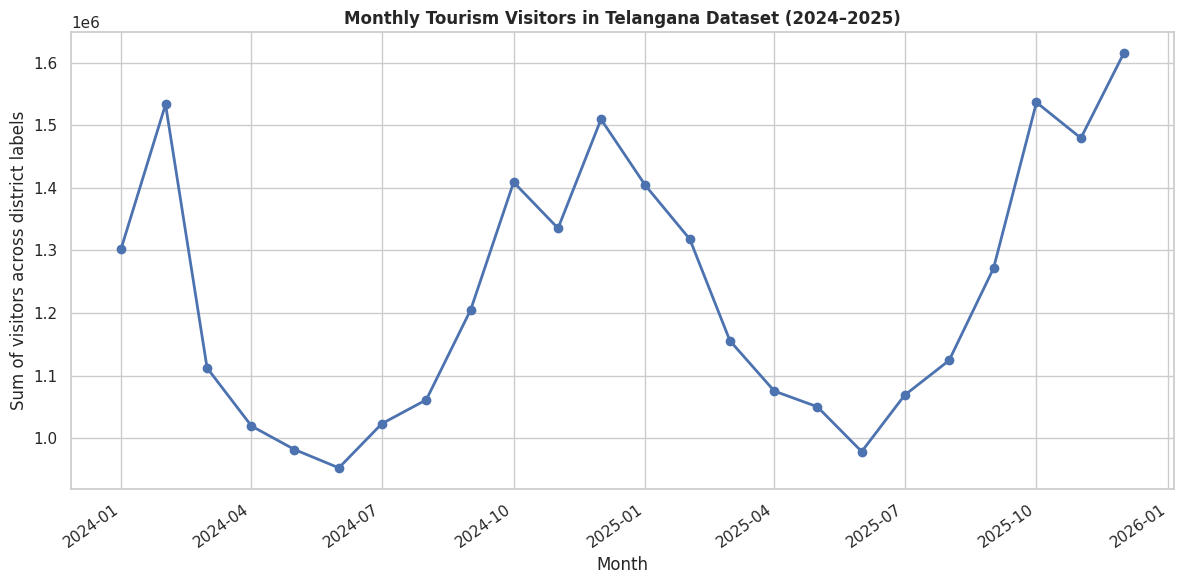

In [7]:
if {"date", "total_visitors"}.issubset(data.columns):
    monthly = (data.dropna(subset=["date"])
               .groupby("date", as_index=False)["total_visitors"].sum()
               .sort_values("date"))
    plt.figure(figsize=(12, 6))
    plt.plot(monthly["date"], monthly["total_visitors"], marker="o", linewidth=2)
    plt.title("Monthly Tourism Visitors in Telangana Dataset (2024–2025)", weight="bold")
    plt.xlabel("Month")
    plt.ylabel("Sum of visitors across district labels")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "05_monthly_visitor_trend.png", dpi=300, bbox_inches="tight")
    plt.show()
    monthly.to_csv(BASE_DIR / "monthly_visitor_summary.csv", index=False)
else:
    print("Trend chart requires date and total_visitors columns.")

## 8. Final project summary and output verification

In [8]:
print("PROJECT SUMMARY")
print("=" * 55)
print(f"Rows in final cleaned dataset: {len(data):,}")
print(f"Columns: {len(data.columns)}")
print(f"District labels: {data['district'].nunique() if 'district' in data.columns else 'Not available'}")
print(f"Regions: {data['region'].nunique() if 'region' in data.columns else 'Not available'}")
print(f"Date range: {data['date'].min().date()} to {data['date'].max().date()}"
      if 'date' in data.columns and data['date'].notna().any() else "Date range: Not available")
print(f"Duplicate rows remaining: {data.duplicated().sum()}")
print(f"Missing cells remaining: {int(data.isna().sum().sum())}")
if "visitor_total_matches_components" in data.columns:
    print("Rows with total = domestic + foreign:",
          f"{int(data['visitor_total_matches_components'].sum())} / {len(data)}")
print("\nSaved visualization files:")
for file in sorted(OUTPUT_DIR.glob("*.png")):
    print(" -", file.name)
print("\nSaved CSV outputs:")
for name in ["cleaned_telangana_tourism.csv", "data_quality_report.csv",
             "district_visitor_summary.csv", "visitor_type_summary.csv",
             "monthly_visitor_summary.csv"]:
    if (BASE_DIR / name).exists():
        print(" -", name)

PROJECT SUMMARY
Rows in final cleaned dataset: 288
Columns: 15
District labels: 12
Regions: 4
Date range: 2024-01-01 to 2025-12-01
Duplicate rows remaining: 0
Missing cells remaining: 0
Rows with total = domestic + foreign: 288 / 288

Saved visualization files:
 - 01_top_10_districts_by_visitors.png
 - 02_monthly_visitors_heatmap.png
 - 03_visitors_by_category_boxplot.png
 - 04_domestic_foreign_visitor_share.png
 - 05_monthly_visitor_trend.png

Saved CSV outputs:
 - cleaned_telangana_tourism.csv
 - data_quality_report.csv
 - district_visitor_summary.csv
 - visitor_type_summary.csv
 - monthly_visitor_summary.csv
